### Weather Analysis

This report is to focus on the relationship between temperature vs. taxi demand

### Import

In [4]:
# Data processing
import pandas as pd

# Data Visualization
import matplotlib.pyplot as plt

# machine learning / regression
from sklearn.linear_model import LinearRegression

from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

# preprocessing
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, root_mean_squared_error, accuracy_score
import numpy as np

# date time
from datetime import datetime

### Data Loading

In [5]:
nyc_weather_hourly = pd.read_csv("../data/raw/nyc_weather_hourly.csv")
yellow_taxi = pd.read_csv("../data/raw/yellow_tripdata_2026-01_cleaned.csv")

/var/folders/6f/wmz_js4n0_vckk43lqnkbd5h0000gn/T/ipykernel_74131/1623600644.py:2: DtypeWarning: Columns (6: store_and_fwd_flag) have mixed types. Specify dtype option on import or set low_memory=False.
  yellow_taxi = pd.read_csv("../data/raw/yellow_tripdata_2026-01_cleaned.csv")


### Table Joining

### Basic inspection into column names and data types

In [6]:
nyc_weather_hourly.columns.tolist()

['date',
 'temperature_2m',
 'precipitation',
 'rain',
 'snowfall',
 'wind_speed_10m']

In [7]:
nyc_weather_hourly.dtypes

date                  str
temperature_2m    float64
precipitation     float64
rain              float64
snowfall          float64
wind_speed_10m    float64
dtype: object

In [8]:
nyc_weather_hourly['date_hour'] = pd.to_datetime(nyc_weather_hourly['date'])
nyc_weather_hourly.head(n=10)

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,date_hour
0,2026-01-01 00:00:00,30.2,0.000,0.0,0.000,8.1,2026-01-01 00:00:00
1,2026-01-01 01:00:00,30.6,0.004,0.0,0.028,8.1,2026-01-01 01:00:00
2,2026-01-01 02:00:00,31.3,0.004,0.0,0.028,8.3,2026-01-01 02:00:00
3,2026-01-01 03:00:00,31.7,0.000,0.0,0.000,8.3,2026-01-01 03:00:00
4,2026-01-01 04:00:00,32.7,0.000,0.0,0.000,8.7,2026-01-01 04:00:00
5,2026-01-01 05:00:00,33.2,0.000,0.0,0.000,9.5,2026-01-01 05:00:00
6,2026-01-01 06:00:00,32.8,0.000,0.0,0.000,9.2,2026-01-01 06:00:00
7,2026-01-01 07:00:00,32.2,0.008,0.0,0.055,10.2,2026-01-01 07:00:00
8,2026-01-01 08:00:00,27.5,0.028,0.0,0.193,13.1,2026-01-01 08:00:00
9,2026-01-01 09:00:00,24.7,0.000,0.0,0.000,13.2,2026-01-01 09:00:00


In [9]:
yellow_taxi.columns.tolist()

['VendorID',
 'tpep_pickup_datetime',
 'tpep_dropoff_datetime',
 'passenger_count',
 'trip_distance',
 'RatecodeID',
 'store_and_fwd_flag',
 'PULocationID',
 'DOLocationID',
 'payment_type',
 'fare_amount',
 'extra',
 'mta_tax',
 'tip_amount',
 'tolls_amount',
 'improvement_surcharge',
 'total_amount',
 'congestion_surcharge',
 'Airport_fee',
 'cbd_congestion_fee',
 'is_negative_total',
 'is_matched_reversal']

In [10]:
yellow_taxi.dtypes

VendorID                   int64
tpep_pickup_datetime         str
tpep_dropoff_datetime        str
passenger_count          float64
trip_distance            float64
RatecodeID               float64
store_and_fwd_flag           str
PULocationID               int64
DOLocationID               int64
payment_type               int64
fare_amount              float64
extra                    float64
mta_tax                  float64
tip_amount               float64
tolls_amount             float64
improvement_surcharge    float64
total_amount             float64
congestion_surcharge     float64
Airport_fee              float64
cbd_congestion_fee       float64
is_negative_total           bool
is_matched_reversal         bool
dtype: object

### Creating a new column for the date_hour

In [11]:
yellow_taxi['date_hour'] = pd.to_datetime(yellow_taxi['tpep_pickup_datetime'])
yellow_taxi.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,is_negative_total,is_matched_reversal,date_hour
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,...,3.66,0.0,1.0,15.86,2.5,0.0,0.00,False,False,2026-01-01 00:54:04
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,...,0.00,0.0,1.0,13.65,2.5,0.0,0.75,False,False,2026-01-01 00:34:04
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,...,2.50,0.0,1.0,18.95,2.5,0.0,0.75,False,False,2026-01-01 00:57:06
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,...,11.11,0.0,1.0,55.56,2.5,0.0,0.75,False,False,2026-01-01 00:15:22
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,...,3.85,0.0,1.0,23.10,2.5,0.0,0.75,False,False,2026-01-01 00:27:13


### Extracting date and hour

In [12]:
nyc_weather_hourly['date'] = nyc_weather_hourly['date_hour'].dt.date
nyc_weather_hourly['hour'] = nyc_weather_hourly['date_hour'].dt.hour

yellow_taxi['date'] = yellow_taxi['date_hour'].dt.date
yellow_taxi['hour'] = yellow_taxi['date_hour'].dt.hour

### Inspecting creation results

In [13]:
nyc_weather_hourly.head()

,date,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,date_hour,hour
0,2026-01-01,30.2,0.000,0.0,0.000,8.1,2026-01-01 00:00:00,0
1,2026-01-01,30.6,0.004,0.0,0.028,8.1,2026-01-01 01:00:00,1
2,2026-01-01,31.3,0.004,0.0,0.028,8.3,2026-01-01 02:00:00,2
3,2026-01-01,31.7,0.000,0.0,0.000,8.3,2026-01-01 03:00:00,3
4,2026-01-01,32.7,0.000,0.0,0.000,8.7,2026-01-01 04:00:00,4


In [14]:
yellow_taxi.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,...,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee,is_negative_total,is_matched_reversal,date_hour,date,hour
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,...,1.0,15.86,2.5,0.0,0.00,False,False,2026-01-01 00:54:04,2026-01-01,0
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,...,1.0,13.65,2.5,0.0,0.75,False,False,2026-01-01 00:34:04,2026-01-01,0
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,...,1.0,18.95,2.5,0.0,0.75,False,False,2026-01-01 00:57:06,2026-01-01,0
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,...,1.0,55.56,2.5,0.0,0.75,False,False,2026-01-01 00:15:22,2026-01-01,0
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,...,1.0,23.10,2.5,0.0,0.75,False,False,2026-01-01 00:27:13,2026-01-01,0


### Aggregate the taxi data together into hours

In [15]:
yellow_taxi_hours = yellow_taxi.groupby(['date', 'hour'], as_index=False).agg(
    trip_count=('tpep_pickup_datetime', 'size'),
    total_revenue=('total_amount', 'sum')
)

yellow_taxi_hours.head()

,date,hour,trip_count,total_revenue
0,2026-01-01,0,9294,295771.15
1,2026-01-01,1,10254,397340.42
2,2026-01-01,2,7853,270398.29
3,2026-01-01,3,6529,210286.78
4,2026-01-01,4,4108,124208.33


### Joining Dataset together to create a merged dataset

In [30]:
df_merged = pd.merge(
    yellow_taxi_hours,
    nyc_weather_hourly,
    on=['date', 'hour'],
    how='inner',
    validate='one_to_one'
)
df_merged["day_of_the_week"] = df_merged["date_hour"].dt.day_name()
df_merged.head(n=10)

,date,hour,trip_count,total_revenue,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,date_hour,day_of_the_week
0,2026-01-01,0,9294,295771.15,30.2,0.000,0.0,0.000,8.1,2026-01-01 00:00:00,Thursday
1,2026-01-01,1,10254,397340.42,30.6,0.004,0.0,0.028,8.1,2026-01-01 01:00:00,Thursday
2,2026-01-01,2,7853,270398.29,31.3,0.004,0.0,0.028,8.3,2026-01-01 02:00:00,Thursday
3,2026-01-01,3,6529,210286.78,31.7,0.000,0.0,0.000,8.3,2026-01-01 03:00:00,Thursday
4,2026-01-01,4,4108,124208.33,32.7,0.000,0.0,0.000,8.7,2026-01-01 04:00:00,Thursday
5,2026-01-01,5,2224,68666.92,33.2,0.000,0.0,0.000,9.5,2026-01-01 05:00:00,Thursday
6,2026-01-01,6,2092,76141.47,32.8,0.000,0.0,0.000,9.2,2026-01-01 06:00:00,Thursday
7,2026-01-01,7,1930,66713.16,32.2,0.008,0.0,0.055,10.2,2026-01-01 07:00:00,Thursday
8,2026-01-01,8,1719,52598.27,27.5,0.028,0.0,0.193,13.1,2026-01-01 08:00:00,Thursday
9,2026-01-01,9,2245,65808.13,24.7,0.000,0.0,0.000,13.2,2026-01-01 09:00:00,Thursday


# Models

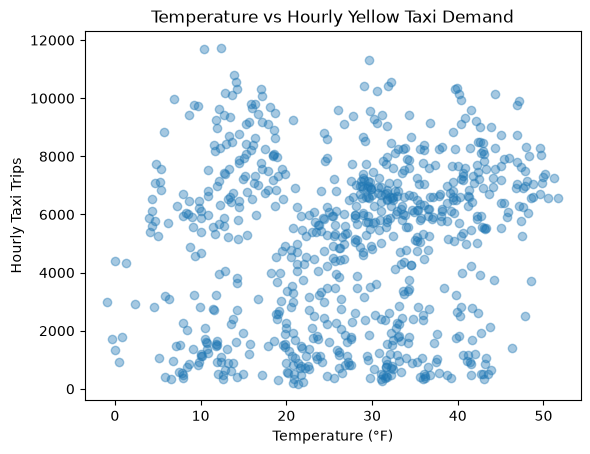

In [31]:
# Look at the relationship between X and y
plt.scatter(
    df_merged['temperature_2m'],
    df_merged['trip_count'],
    alpha=0.4
)

plt.xlabel("Temperature (°F)")
plt.ylabel("Hourly Taxi Trips")
plt.title("Temperature vs Hourly Yellow Taxi Demand")

plt.show()

In [32]:
# Calculate the correlation
df_merged['temperature_2m'].corr(df_merged['trip_count'])

np.float64(0.13408655339508396)

## Linear Model

Theory: $Y = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + ... + \beta_p x_p + \epsilon$

Usual methods: Minimize the residual sum of squares (RSS)

Linear Model Assumptions:

* Linearity: The target is a linear combination of the features, plus an error term
* Independence: The errors are independent
* Normality: The errors are normally distributed
* Equal Variance: The errors have constant variance

Implicit Assumptions:

* No perfect multicollinearity
* Fixed x
* More samples than features

The purpose of this model is to use columns information to predict the demand of taxi usage, which is total trip count.

In [ ]:
# Data split on time
df_sorted = df_merged.sort_values(by="date_hour", ascending=True).copy()

split_index = int(len(df_sorted) * 0.8)
df_train = df_sorted.iloc[:split_index]
df_test = df_sorted.iloc[split_index:]

# Preprocessing
numeric_features = ["temperature_2m", "precipitation", "snowfall", "wind_speed_10m"]
categorical_features = ["hour", "day_of_the_week"]
features = numeric_features + categorical_features

X_train = df_train[features]
y_train = df_train["trip_count"]

X_test = df_test[features]
y_test = df_test["trip_count"]

Notes:

We did not include date and date_hour because it would encourage the model to learn the noise that are specific to Janurary rather than learning the general demand behavior.

We did not include total revenue inside the data because that would be considered as data leakeage. Since total revenue is directly correlated with taxi trip count in real life.

We created the column day of the week and then included that into the categorical features because it is a repeating pattern that generalizes beyond Janurary.

For data splitting. We are going to split based on time because we are trying to use the past to predict the future.

## Non-linear regression models

### Random Forrest